# Background

- **Author**: 許以琳
- **Created At**: 2026-11-10
- **Research Motivation and Context (why are we interested in the findings?)：** 與 [candidate_kmeans_elbow.ipynb](candidate_kmeans_elbow.ipynb)、[candidate_pam_gower.ipynb](candidate_pam_gower.ipynb)、[candidate_cluster_education_ordinal.ipynb](candidate_cluster_education_ordinal.ipynb) 相同的 267 人樣本（全部縣市長＋臺北、高雄議員）與相同的 k-means、PAM 設定，但改用 **G6 已依組員張睿庠資料更新** 的分析檔 `data/processed/candidates_scope_g1_g6_20261110.csv`（產生方式見 [G6 更新處理筆記本](../data/code/apply_g6_teammate_20261110.ipynb)：31 人 G6 由 0 改為 1）。本 notebook 一次完成兩種方法的選 k、最終分群、穩定度、學歷順序編碼敏感度，並重算舊版 G6 以便比較；舊版 notebook 保留不改。
- **Main Findings and Takeaways：** G6 改用組員資料後（267 人中 31 人由 0 改 1，政治家族比例 21.0% → 32.6%）：(1) k-means 切點仍是 k = 4，分群和舊版完全相同（ARI 1.000）：大學學歷跨黨（70）、國民黨（68）、無黨籍／小黨（65）、民進黨（64），仍主要反映政黨與學歷。(2) PAM 切點變成 k = 3（離連線 20.31，k = 4 為 20.18，幾乎相同）：男性、國民黨為主（126）、女性＋政治家族（86，女性 80%、政治家族 74%）、無黨籍素人（55，無黨籍 75%、首次參選 71%）；k = 4 為男性國民黨為主（83）、女性＋政治家族（82）、年長大學學歷無黨籍（54，58.9 歲）、首次參選無黨籍（48，首次 85%）。舊版 PAM k = 4 的「女性」群現在幾乎就是「女性＋政治家族」群。(3) PAM 比舊版穩定（抽樣重跑平均 ARI：k = 3 為 0.687、k = 4 為 0.587；舊版 0.458），但仍低於 k-means（0.897）；PAM k = 3 與 G5×G6 組合的 ARI 為 0.357。(4) 學歷改順序編碼：k-means 變成純政黨（85／80／69／33，和政黨 ARI 0.986）；PAM 切點為 3，k = 4 和類別版 ARI 0.777、抽樣重跑 0.807，結果比舊版 G6 時穩定許多。
- **Future Direction：** 後續分群與策略比較改用本版 G6；與北高版（[candidate_cluster_taipei_kaohsiung_g6v2.ipynb](candidate_cluster_taipei_kaohsiung_g6v2.ipynb)）及組員 G5×G6 分組比較；沈伯洋、陳瑩、許甫、吳銘賜 4 人的 G6 定義邊界仍可討論。
<!-- Deliver the ipynb in finding/ directly for review, retaining actual outputs.
HTML is not required and is produced only when separately requested. Use the
student's requested or existing filename, or a descriptive basename. Created At
is the fixed creation date. Follow the project-root FINDING-RULES.md for handoff
and external-action scope. -->


In [1]:
# Load packages here
from pathlib import Path
import hashlib
from math import comb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei", "Microsoft YaHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
# 本機 Windows 的應用程式控制原則封鎖 scikit-learn 的編譯元件，k-means、PAM、輪廓係數與 ARI 以 numpy 實作（與先前 notebook 相同）。


In [2]:
# Load input data here and please finish all the data manipulation here.
def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "AGENTS.md").is_file() and (candidate / "templates").is_dir():
            return candidate
    raise FileNotFoundError("請在含 AGENTS.md 與 templates/ 的專案內開啟本 notebook。")

PROJECT_ROOT = find_project_root()
DATA_REL = "data/processed/candidates_scope_g1_g6_20261110.csv"
EXPECTED_SHA256 = "ff2a7214ccaeb86a2ea2b5caf1883cb07aa7f37454505d76f221b6f6ac0c7ea0"
OLD_REL = "data/processed/candidates_scope_g1_g6_20261108.csv"
OLD_SHA256 = "5af31805a707502198004aad222ac9a61c4309d9bc27cfa1c059450d74b8e6a6"
data_path = PROJECT_ROOT / DATA_REL
assert data_path.is_file(), f"找不到輸入檔：{DATA_REL}"
actual = hashlib.sha256(data_path.read_bytes()).hexdigest()
assert actual == EXPECTED_SHA256, f"輸入檔內容已變動（{actual}），請先確認新版本再分析。"

raw = pd.read_csv(data_path, dtype=str, encoding="utf-8-sig")
old_path = PROJECT_ROOT / OLD_REL
assert hashlib.sha256(old_path.read_bytes()).hexdigest() == OLD_SHA256, "舊版分析檔內容已變動"
raw_old = pd.read_csv(old_path, dtype=str, encoding="utf-8-sig")
need = ["candidate_key", "candidate_name", "office_type", "county_city", "G1_age_2026_minus_birth_year",
        "G1_age_basis", "G2_sex", "G3_education_level", "G4_party",
        "G5_first_time_any_elected_office", "G6_political_family"]
assert set(need) <= set(raw.columns) and raw["candidate_key"].is_unique

def prep(frame):
    d = frame[need].copy().reset_index(drop=True)
    d["age"] = pd.to_numeric(d["G1_age_2026_minus_birth_year"], errors="raise")
    d["sex"] = d["G2_sex"]
    d["education"] = d["G3_education_level"]
    d["party"] = d["G4_party"]
    d["first_time"] = d["G5_first_time_any_elected_office"].map({"1": "首次參選", "0": "曾參選"})
    d["political_family"] = d["G6_political_family"].map({"1": "有", "0": "無"})
    return d

df_old = prep(raw_old)   # 舊版 G6（對照用）
df = prep(raw)  # 本分析：267 人（全部縣市長＋臺北、高雄議員）
analysis_vars = ["age", "sex", "education", "party", "first_time", "political_family"]
assert df[analysis_vars].notna().all().all()
assert (df_old["candidate_key"].to_numpy() == df["candidate_key"].to_numpy()).all()
print("分析樣本（全部縣市長＋北高議員）：", len(df), "人；G6 由舊版改為 1 的人數：", int(((df_old["political_family"] == "無") & (df["political_family"] == "有")).sum()))
print(pd.crosstab(df["county_city"], df["office_type"], margins=True, margins_name="合計"))
df[["candidate_name", "office_type", "county_city"] + analysis_vars].head(10)


分析樣本（全部縣市長＋北高議員）： 267 人；G6 由舊版改為 1 的人數： 31
office_type  直轄市議員  直轄市長  縣（市）長   合計
county_city                         
南投縣              0     0      2    2
嘉義市              0     0      5    5
嘉義縣              0     0      2    2
基隆市              0     0      2    2
宜蘭縣              0     0      5    5
屏東縣              0     0      2    2
彰化縣              0     0      4    4
新北市              0     3      0    3
新竹市              0     0      3    3
新竹縣              0     0      3    3
桃園市              0     2      0    2
澎湖縣              0     0      6    6
臺中市              0     3      0    3
臺北市             90     6      0   96
臺南市              0     4      0    4
臺東縣              0     0      4    4
花蓮縣              0     0      4    4
苗栗縣              0     0      2    2
連江縣              0     0      2    2
金門縣              0     0      7    7
雲林縣              0     0      4    4
高雄市             97     5      0  102
合計             187    23     57  267


,candidate_name,office_type,county_city,age,sex,education,party,first_time,political_family
0,郭璽,直轄市長,臺北市,68,男,大學,其他政黨,曾參選,無
1,沈伯洋,直轄市長,臺北市,44,男,研究所,民進黨,曾參選,有
2,蕭文乾,直轄市長,臺北市,52,男,研究所,其他政黨,曾參選,無
3,唐新民,直轄市長,臺北市,76,男,研究所,其他政黨,曾參選,無
4,蔣萬安,直轄市長,臺北市,48,男,研究所,國民黨,曾參選,有
5,林志成,直轄市長,臺北市,61,男,研究所,無黨籍／未經政黨推薦,曾參選,無
6,蘇巧慧,直轄市長,新北市,50,女,研究所,民進黨,曾參選,有
7,李四川,直轄市長,新北市,68,男,研究所,國民黨,首次參選,無
8,蘇輝湟,直轄市長,新北市,50,男,大學,無黨籍／未經政黨推薦,曾參選,無
9,張善政,直轄市長,桃園市,72,男,研究所,國民黨,曾參選,無


In [3]:
# Before conducting the analysis, report summary statistics for all variables used.
LABELS = {"age": "G1 年齡（2026 − 出生年）", "sex": "G2 性別", "education": "G3 最高已完成學歷",
          "party": "G4 政黨（登記推薦）", "first_time": "G5 是否首次參選任何民選公職",
          "political_family": "G6 政治家族（配偶或三親等內親屬任公職）"}
N = len(df)
d = df["age"].describe(percentiles=[.25, .5, .75])
print(f"表 1　數值變數摘要統計（N = {N}）")
display(pd.DataFrame({"平均": [d["mean"]], "最小值": [d["min"]], "第25百分位": [d["25%"]], "中位數": [d["50%"]],
                      "第75百分位": [d["75%"]], "最大值": [d["max"]], "標準差": [d["std"]], "有效 N": [int(d["count"])],
                      "缺值 N": [int(df["age"].isna().sum())]}, index=[LABELS["age"]]).round(2))
rows = []
for v in ["sex", "education", "party", "first_time", "political_family"]:
    vc = df[v].value_counts(); nn = int(df[v].notna().sum())
    for cat, cnt in vc.head(10).items():
        rows.append({"變數": LABELS[v], "類別": cat, "人數": int(cnt), "百分比（%）": round(100 * cnt / nn, 1),
                     "有效 N": nn, "缺值 N": int(df[v].isna().sum())})
print(f"表 2　類別變數摘要統計（N = {N}；百分比分母為該變數非缺值人數）")
display(pd.DataFrame(rows).set_index(["變數", "類別"]))


表 1　數值變數摘要統計（N = 267）


,平均,最小值,第25百分位,中位數,第75百分位,最大值,標準差,有效 N,缺值 N
G1 年齡（2026 − 出生年）,52.02,24.0,43.5,52.0,61.0,83.0,11.62,267,0


表 2　類別變數摘要統計（N = 267；百分比分母為該變數非缺值人數）


人數  百分比（%）  有效 N  缺值 N
變數                    類別                                 
G2 性別                 男           167    62.5   267     0
                      女           100    37.5   267     0
G3 最高已完成學歷            研究所         169    63.3   267     0
                      大學           70    26.2   267     0
                      大學以下         28    10.5   267     0
G4 政黨（登記推薦）           國民黨          85    31.8   267     0
                      民進黨          80    30.0   267     0
                      無黨籍／未經政黨推薦   69    25.8   267     0
                      其他政黨         25     9.4   267     0
                      民眾黨           8     3.0   267     0
G5 是否首次參選任何民選公職       曾參選         208    77.9   267     0
                      首次參選         59    22.1   267     0
G6 政治家族（配偶或三親等內親屬任公職） 無           180    67.4   267     0
                      有            87    32.6   267     0

### The actual analysis starts below

**設定與舊版 G6 的 267 人分析完全相同，只換 G6。**

- **k-means**：G1 年齡以本樣本的最小、最大值縮放到 0–1；G2 女性＝1；G3 學歷拆 3 欄、G4 政黨拆 5 欄（0/1）；G5、G6 為 0/1，共 12 欄。每個 k 試 50 組 k-means++ 起點，取群內平方和（WCSS）最小的解。
- **PAM**：Gower 距離，年齡差距 ÷ 本樣本年齡全距，其餘五個類別變數相同 0、不同 1，六項平均；BUILD＋SWAP 求代表人物（medoid）。

**選 k。** 兩種方法都跑 k = 1–10，以平移首尾連線找 elbow 切點，並看平均輪廓係數與最小群人數。最終分群採各自的 elbow 切點；若切點不是 4，另列 k = 4 的結果以便和 267 人版本比較。

**穩定度與比較。** 抽 80% 重跑 50 次、排除年齡來自報導或約略值者重跑；並和舊版 G6 的分群比較（ARI，同一批 198 人）。


In [4]:
PARTIES = ["國民黨", "民進黨", "民眾黨", "其他政黨", "無黨籍／未經政黨推薦"]

def feat(frame):
    amin, amax = frame["age"].min(), frame["age"].max()
    X = pd.DataFrame(index=frame.index)
    X["age"] = (frame["age"] - amin) / (amax - amin)
    X["female"] = (frame["sex"] == "女").astype(int)
    for lvl in ["大學以下", "大學", "研究所"]:
        X[lvl] = (frame["education"] == lvl).astype(int)
    for p in PARTIES:
        X[p] = (frame["party"] == p).astype(int)
    X["first"] = (frame["first_time"] == "首次參選").astype(int)
    X["family"] = (frame["political_family"] == "有").astype(int)
    return X.values.astype(float)

def gower(frame, age_range=None):
    a = frame["age"].to_numpy(float)
    r = (a.max() - a.min()) if age_range is None else age_range
    Dm = np.abs(a[:, None] - a[None, :]) / r
    for v in ["sex", "education", "party", "first_time", "political_family"]:
        x = frame[v].to_numpy()
        Dm = Dm + (x[:, None] != x[None, :])
    return Dm / 6

def kmeans(X, k, n_init=50, max_iter=300, tol=1e-8, seed=0):
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(n_init):
        Cc = [X[rng.integers(len(X))]]
        for _ in range(1, k):
            d2 = np.min(((X[:, None, :] - np.array(Cc)[None]) ** 2).sum(-1), axis=1)
            Cc.append(X[rng.choice(len(X), p=d2 / d2.sum())] if d2.sum() > 0 else X[rng.integers(len(X))])
        Cc = np.array(Cc, dtype=float)
        for _ in range(max_iter):
            lab = ((X[:, None, :] - Cc[None]) ** 2).sum(-1).argmin(1)
            newC = np.array([X[lab == j].mean(0) if (lab == j).any() else Cc[j] for j in range(k)])
            shift = ((newC - Cc) ** 2).sum()
            Cc = newC
            if shift <= tol:
                break
        lab = ((X[:, None, :] - Cc[None]) ** 2).sum(-1).argmin(1)
        inertia = ((X - Cc[lab]) ** 2).sum()
        if best is None or inertia < best[1] - 1e-12:
            best = (lab, inertia)
    return best

def pam(Dm, k, max_iter=200):
    n = len(Dm)
    med = [int(Dm.sum(1).argmin())]
    while len(med) < k:
        dmin = Dm[:, med].min(1)
        gain = np.maximum(dmin[None, :] - Dm, 0).sum(1)
        gain[med] = -1
        med.append(int(gain.argmax()))
    med = np.array(med)
    for _ in range(max_iter):
        dm = Dm[:, med]
        order = np.argsort(dm, axis=1)
        near = order[:, 0]
        d1 = dm[np.arange(n), near]
        d2 = dm[np.arange(n), order[:, 1]] if k > 1 else np.full(n, np.inf)
        cost = d1.sum()
        best = (0.0, None, None)
        nonmed = np.setdiff1d(np.arange(n), med)
        for i in range(k):
            base = np.where(near == i, d2, d1)
            newc = np.minimum(Dm[nonmed, :], base[None, :]).sum(1) - cost
            j = newc.argmin()
            if newc[j] < best[0] - 1e-12:
                best = (newc[j], i, nonmed[j])
        if best[1] is None:
            break
        med[best[1]] = best[2]
    lab = Dm[:, med].argmin(1)
    return lab, Dm[np.arange(n), med[lab]].sum(), med

def silhouette_D(Dm, lab):
    s = np.zeros(len(Dm))
    for i in range(len(Dm)):
        same = lab == lab[i]
        if same.sum() <= 1:
            continue
        a = Dm[i, same].sum() / (same.sum() - 1)
        b = min(Dm[i, lab == c].mean() for c in np.unique(lab) if c != lab[i])
        s[i] = 0 if max(a, b) == 0 else (b - a) / max(a, b)
    return s.mean()

def eucl(X):
    return np.sqrt(((X[:, None, :] - X[None]) ** 2).sum(-1))

def ari(a, b):
    ct = pd.crosstab(pd.Series(list(a)), pd.Series(list(b))).values
    sij = sum(comb(int(n), 2) for n in ct.ravel())
    sa = sum(comb(int(n), 2) for n in ct.sum(1)); sb = sum(comb(int(n), 2) for n in ct.sum(0))
    tot = comb(int(ct.sum()), 2); e = sa * sb / tot
    return (sij - e) / ((sa + sb) / 2 - e)

def tangent(series):
    ks = np.array(series.index, float)
    chord = series.iloc[0] + (series.iloc[-1] - series.iloc[0]) / (ks[-1] - ks[0]) * (ks - ks[0])
    gap = pd.Series(chord - series.values, index=series.index)
    return int(gap.idxmax()), gap

def relabel(lab):
    order = pd.Series(lab).value_counts().index.tolist()
    return pd.Series(lab).map({o: i + 1 for i, o in enumerate(order)}).values

X = feat(df); D = gower(df); Eu = eucl(X)
print(f"k-means 特徵矩陣 {X.shape}；Gower 距離 {D.shape}，兩兩平均 {D[np.triu_indices(len(D), 1)].mean():.3f}")

rows = []
for k in range(1, 11):
    lk, wk = kmeans(X, k, n_init=50, seed=20261110 + k)
    lp, cp, _ = pam(D, k)
    rows.append({"k": k, "k-means WCSS": wk, "k-means 輪廓係數": silhouette_D(Eu, lk) if k > 1 else np.nan,
                 "k-means 最小群": int(np.bincount(lk, minlength=k).min()),
                 "PAM 總成本": cp, "PAM 輪廓係數": silhouette_D(D, lp) if k > 1 else np.nan,
                 "PAM 最小群": int(np.bincount(lp, minlength=k).min())})
ch = pd.DataFrame(rows).set_index("k")
ch.insert(1, "k-means 減少（%）", 100 * (-ch["k-means WCSS"].diff()) / ch["k-means WCSS"].shift())
ch.insert(5, "PAM 減少（%）", 100 * (-ch["PAM 總成本"].diff()) / ch["PAM 總成本"].shift())
K_KM, gap_km = tangent(ch["k-means WCSS"])
K_PAM, gap_pam = tangent(ch["PAM 總成本"])
print(f"表 3　全部縣市長＋北高議員：k = 1–10 的 WCSS／總成本、輪廓係數與最小群（N = {len(df)}）")
display(ch.round(3))
print(f"平移首尾連線切點：k-means k = {K_KM}（離連線 {gap_km.max():.2f}）；PAM k = {K_PAM}（離連線 {gap_pam.max():.2f}）")
print("k-means 各 k 離連線距離：", gap_km.round(2).to_dict())
print("PAM 各 k 離連線距離：", gap_pam.round(2).to_dict())


k-means 特徵矩陣 (267, 12)；Gower 距離 (267, 267)，兩兩平均 0.457


表 3　全部縣市長＋北高議員：k = 1–10 的 WCSS／總成本、輪廓係數與最小群（N = 267）


,k-means WCSS,k-means 減少（%）,k-means 輪廓係數,k-means 最小群,PAM 總成本,PAM 減少（%）,PAM 輪廓係數,PAM 最小群
k,,,,,,,,
1,511.782,NaN,NaN,267,94.932,NaN,NaN,267
2,406.656,20.541,0.233,98,73.243,22.847,0.281,110
3,346.174,14.873,0.257,81,61.268,16.349,0.237,55
4,293.283,15.279,0.271,64,54.718,10.692,0.219,48
5,261.266,10.917,0.294,28,50.308,8.059,0.225,43
6,243.502,6.799,0.306,22,46.150,8.265,0.222,37
7,224.499,7.804,0.322,13,42.983,6.862,0.232,29
8,206.254,8.127,0.316,20,40.073,6.769,0.246,21
9,191.470,7.168,0.337,15,37.274,6.986,0.261,22


平移首尾連線切點：k-means k = 4（離連線 108.22）；PAM k = 3（離連線 20.31）
k-means 各 k 離連線距離： {1: 0.0, 2: 68.37, 3: 92.09, 4: 108.22, 5: 103.48, 6: 84.48, 7: 66.72, 8: 48.21, 9: 26.23, 10: 0.0}
PAM 各 k 離連線距離： {1: 0.0, 2: 15.01, 3: 20.31, 4: 20.18, 5: 17.91, 6: 15.4, 7: 11.89, 8: 8.12, 9: 4.24, 10: 0.0}


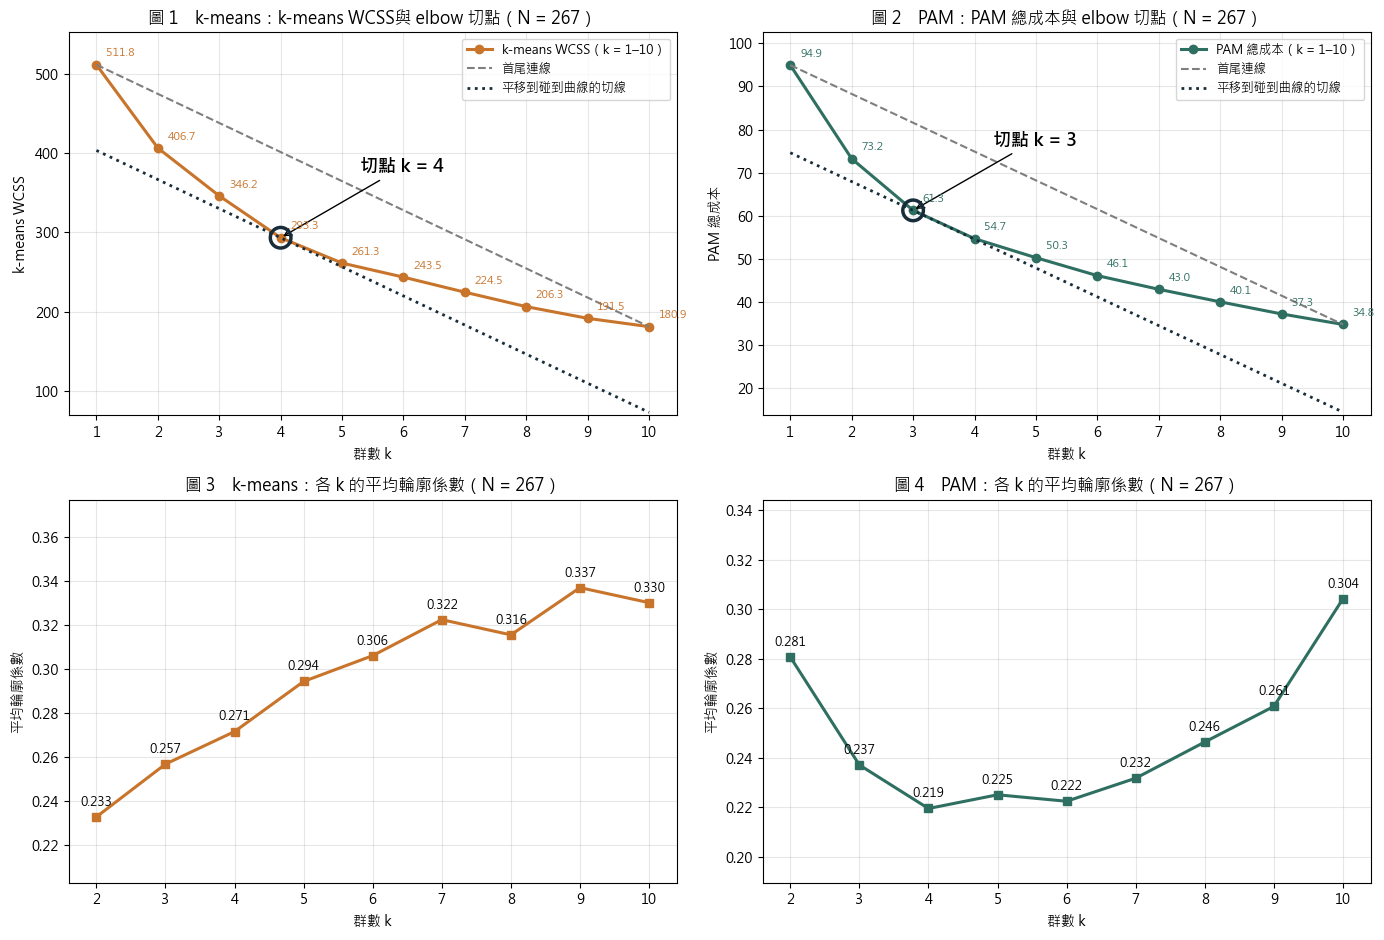

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))
for col_i, (col, sil, kk, gap, color, name) in enumerate([
        ("k-means WCSS", "k-means 輪廓係數", K_KM, gap_km, "#C8742B", "k-means"),
        ("PAM 總成本", "PAM 輪廓係數", K_PAM, gap_pam, "#2f6f62", "PAM")]):
    ax = axes[0, col_i]
    w = ch[col]; ks = np.array(w.index, float)
    chord = w.iloc[0] + (w.iloc[-1] - w.iloc[0]) / 9 * (ks - 1)
    ax.plot(ks, w.values, marker="o", color=color, linewidth=2.2, label=f"{col}（k = 1–10）")
    ax.plot([1, 10], [w.iloc[0], w.iloc[-1]], linestyle="--", color="#7f7f7f", label="首尾連線")
    ax.plot(ks, chord - gap.max(), linestyle=":", color="#182D39", linewidth=2, label="平移到碰到曲線的切線")
    ax.scatter([kk], [w.loc[kk]], s=220, facecolors="none", edgecolors="#182D39", linewidths=2.5, zorder=4)
    ax.annotate(f"切點 k = {kk}", xy=(kk, w.loc[kk]), xytext=(kk + 1.3, w.loc[kk] + (w.max() - w.min()) * 0.25),
                fontsize=13, fontweight="bold", arrowprops=dict(arrowstyle="->"))
    for k, v in w.items():
        ax.annotate(f"{v:.1f}", (k, v), textcoords="offset points", xytext=(7, 6), fontsize=8, color=color)
    ax.set_title(f"圖 {1 + col_i}　{name}：{col}與 elbow 切點（N = {len(df)}）")
    ax.set_xlabel("群數 k"); ax.set_ylabel(col); ax.set_xticks(ks)
    ax.set_ylim(min((chord - gap.max()).min(), w.min()) * 0.95, w.max() * 1.08)
    ax.legend(loc="upper right", fontsize=9); ax.grid(alpha=.3)
    ax = axes[1, col_i]
    s = ch[sil].dropna()
    ax.plot(s.index, s.values, marker="s", color=color, linewidth=2.2)
    for k, v in s.items():
        ax.annotate(f"{v:.3f}", (k, v), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
    ax.set_title(f"圖 {3 + col_i}　{name}：各 k 的平均輪廓係數（N = {len(df)}）")
    ax.set_xlabel("群數 k"); ax.set_ylabel("平均輪廓係數"); ax.set_xticks(s.index)
    ax.set_ylim(s.min() - 0.03, s.max() + 0.04); ax.grid(alpha=.3)
fig.tight_layout()
asset_dir = PROJECT_ROOT / "finding" / "candidate_cluster_all_g6v2_assets"
asset_dir.mkdir(exist_ok=True)
fig.savefig(asset_dir / "all_choose_k.png", dpi=200)
plt.show()


In [6]:
def describe(g):
    col = {"人數": len(g), "平均年齡": g["age"].mean(), "女性（%）": 100 * (g["sex"] == "女").mean()}
    for lvl in ["研究所", "大學", "大學以下"]:
        col[f"學歷：{lvl}（%）"] = 100 * (g["education"] == lvl).mean()
    for pty in PARTIES:
        col[f"政黨：{pty}（%）"] = 100 * (g["party"] == pty).mean()
    col["首次參選（%）"] = 100 * (g["first_time"] == "首次參選").mean()
    col["政治家族（%）"] = 100 * (g["political_family"] == "有").mean()
    col["首長（%）"] = 100 * (g["office_type"] != "直轄市議員").mean()
    col["北高議員（%）"] = 100 * (g["office_type"] == "直轄市議員").mean()
    return col

results = {}
versions = [("k-means", K_KM), ("PAM", K_PAM)]
if K_KM != 4:
    versions.append(("k-means", 4))
if K_PAM != 4:
    versions.append(("PAM", 4))
for method, k in versions:
    if method == "k-means":
        lab = relabel(kmeans(X, k, n_init=50, seed=20261110 + k)[0]); med = None
    else:
        l, _, med = pam(D, k); lab = relabel(l)
    name = f"{method} k = {k}"
    results[name] = {"lab": lab, "k": k, "method": method, "med": med, "raw": None if med is None else l}
    df["_c"] = lab
    prof = pd.DataFrame({f"第 {c} 群": describe(g) for c, g in df.groupby("_c")})
    prof["全樣本"] = pd.Series(describe(df))
    results[name]["profile"] = prof
    print(f"表　{name}（N = {len(df)}）各群特徵；百分比分母為該群人數")
    display(prof.round(1))
    if med is not None:
        rel = {o: i + 1 for i, o in enumerate(pd.Series(l).value_counts().index.tolist())}
        mt = df.iloc[med][["candidate_name", "office_type", "county_city", "age", "sex", "education", "party", "first_time", "political_family"]].copy()
        mt.insert(0, "群別", [f"第 {rel[i]} 群" for i in range(k)])
        print(f"　{name} 各群代表人物（medoid）")
        display(mt.sort_values("群別").set_index("群別"))
df = df.drop(columns="_c")


表　k-means k = 4（N = 267）各群特徵；百分比分母為該群人數


,第 1 群,第 2 群,第 3 群,第 4 群,全樣本
人數,70.0,68.0,65.0,64.0,267.0
平均年齡,49.3,54.2,55.1,49.5,52.0
女性（%）,34.3,44.1,26.2,45.3,37.5
學歷：研究所（%）,0.0,91.2,69.2,96.9,63.3
學歷：大學（%）,100.0,0.0,0.0,0.0,26.2
學歷：大學以下（%）,0.0,8.8,30.8,3.1,10.5
政黨：國民黨（%）,24.3,100.0,0.0,0.0,31.8
政黨：民進黨（%）,24.3,0.0,0.0,98.4,30.0
政黨：民眾黨（%）,7.1,0.0,3.1,1.6,3.0
政黨：其他政黨（%）,14.3,0.0,23.1,0.0,9.4


表　PAM k = 3（N = 267）各群特徵；百分比分母為該群人數


,第 1 群,第 2 群,第 3 群,全樣本
人數,126.0,86.0,55.0,267.0
平均年齡,55.4,47.3,51.7,52.0
女性（%）,18.3,80.2,14.5,37.5
學歷：研究所（%）,72.2,73.3,27.3,63.3
學歷：大學（%）,16.7,20.9,56.4,26.2
學歷：大學以下（%）,11.1,5.8,16.4,10.5
政黨：國民黨（%）,49.2,25.6,1.8,31.8
政黨：民進黨（%）,20.6,55.8,10.9,30.0
政黨：民眾黨（%）,2.4,3.5,3.6,3.0
政黨：其他政黨（%）,11.9,5.8,9.1,9.4


　PAM k = 3 各群代表人物（medoid）


,candidate_name,office_type,county_city,age,sex,education,party,first_time,political_family
群別,,,,,,,,,
第 1 群,吳宗憲,縣（市）長,宜蘭縣,55,男,研究所,國民黨,曾參選,無
第 2 群,鍾佩玲,直轄市議員,臺北市,47,女,研究所,民進黨,曾參選,有
第 3 群,李吳穎智,縣（市）長,臺東縣,47,男,大學,無黨籍／未經政黨推薦,首次參選,無


表　PAM k = 4（N = 267）各群特徵；百分比分母為該群人數


,第 1 群,第 2 群,第 3 群,第 4 群,全樣本
人數,83.0,82.0,54.0,48.0,267.0
平均年齡,54.0,47.4,58.9,48.8,52.0
女性（%）,19.3,79.3,20.4,16.7,37.5
學歷：研究所（%）,84.3,74.4,14.8,62.5,63.3
學歷：大學（%）,8.4,19.5,70.4,18.8,26.2
學歷：大學以下（%）,7.2,6.1,14.8,18.8,10.5
政黨：國民黨（%）,63.9,26.8,11.1,8.3,31.8
政黨：民進黨（%）,22.9,59.8,9.3,14.6,30.0
政黨：民眾黨（%）,2.4,2.4,5.6,2.1,3.0
政黨：其他政黨（%）,9.6,2.4,20.4,8.3,9.4


　PAM k = 4 各群代表人物（medoid）


,candidate_name,office_type,county_city,age,sex,education,party,first_time,political_family
群別,,,,,,,,,
第 1 群,吳宗憲,縣（市）長,宜蘭縣,55,男,研究所,國民黨,曾參選,無
第 2 群,鍾佩玲,直轄市議員,臺北市,47,女,研究所,民進黨,曾參選,有
第 3 群,吳炳輝,縣（市）長,雲林縣,59,男,大學,無黨籍／未經政黨推薦,曾參選,無
第 4 群,朱政騏,直轄市議員,臺北市,48,男,研究所,無黨籍／未經政黨推薦,首次參選,無


表　穩定度（N = 267；抽 80%＝214 人重跑 50 次；排除報導／約略年齡者 N = 245）


,抽 80% 重跑平均 ARI,最低 ARI,ARI ≥ 0.9（%）,排除約略年齡後 ARI,輪廓係數
版本,,,,,
k-means k = 4,0.897,0.599,64.0,0.990,0.271
PAM k = 3,0.687,0.108,34.0,0.617,0.237
PAM k = 4,0.587,0.157,28.0,1.000,0.219


表　與舊版 G6、政黨、G5×G6 組合的一致程度（N = 267）；本樣本 k-means 與 PAM（各自切點）之間 ARI = 0.103


,與舊版 G6 同版本的 ARI,與舊版 G6 同方法切點版的 ARI,與政黨本身的 ARI,與 G5×G6 組合的 ARI
版本,,,,
k-means k = 4,1.0,1.000,0.543,0.020
PAM k = 3,NaN,0.352,0.169,0.357
PAM k = 4,0.2,0.200,0.228,0.293


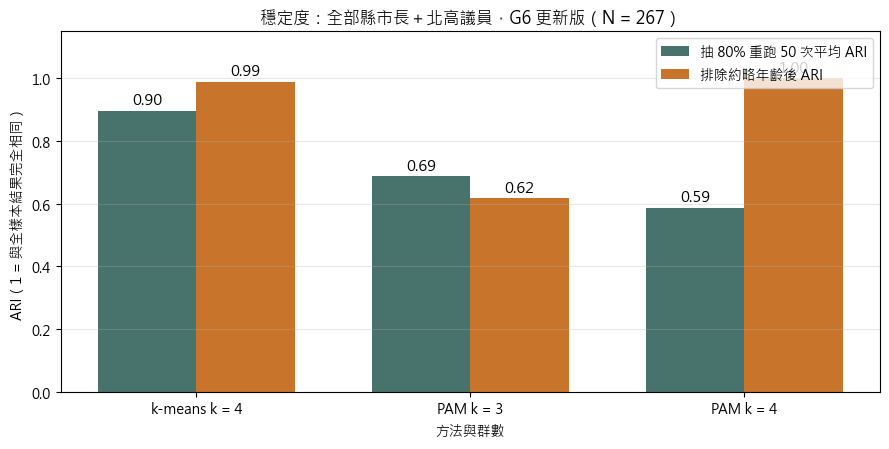

In [7]:
# 穩定度：抽 80% 重跑 50 次（兩方法同一批抽樣）、排除報導／約略年齡者重跑
rng = np.random.default_rng(20261110)
n = len(df); m = int(round(0.8 * n))
age_range = df["age"].max() - df["age"].min()
keep = np.where(df["G1_age_basis"].isin(["birth_date", "existing_source"]).to_numpy())[0]
srows = []
for name, r in results.items():
    k = r["k"]; boot = []
    rng = np.random.default_rng(20261110)
    for rep in range(50):
        idx = np.sort(rng.choice(n, m, replace=False))
        if r["method"] == "k-means":
            l = kmeans(X[idx], k, n_init=10, seed=20261110 + 100 + rep)[0]
        else:
            l = pam(D[np.ix_(idx, idx)], k)[0]
        boot.append(ari(r["lab"][idx], l))
    boot = np.array(boot)
    if r["method"] == "k-means":
        le = kmeans(X[keep], k, n_init=50, seed=20261110 + k)[0]
    else:
        le = pam(D[np.ix_(keep, keep)], k)[0]
    srows.append({"版本": name, "抽 80% 重跑平均 ARI": boot.mean(), "最低 ARI": boot.min(),
                  "ARI ≥ 0.9（%）": 100 * (boot >= 0.9).mean(), "排除約略年齡後 ARI": ari(r["lab"][keep], le),
                  "輪廓係數": silhouette_D(Eu if r["method"] == "k-means" else D, r["lab"])})
stab_tbl = pd.DataFrame(srows).set_index("版本")
print(f"表　穩定度（N = {n}；抽 80%＝{m} 人重跑 50 次；排除報導／約略年齡者 N = {len(keep)}）")
display(stab_tbl.round(3))

# 和舊版 G6 比較（同一批 198 人；舊版切點 k-means 4、PAM 5，並列 PAM 4）
X_old = feat(df_old); D_old = gower(df_old)
old_labels = {"k-means k = 4": relabel(kmeans(X_old, 4, n_init=50, seed=20261110 + 4)[0]),
              "PAM k = 4": relabel(pam(D_old, 4)[0])}
assert sorted(pd.Series(old_labels["k-means k = 4"]).value_counts().tolist()) == [64, 65, 68, 70]
assert sorted(pd.Series(old_labels["PAM k = 4"]).value_counts().tolist()) == [51, 66, 74, 76]
crows = []
for name, r in results.items():
    same = old_labels.get(name)
    crows.append({"版本": name,
                  "與舊版 G6 同版本的 ARI": ari(r["lab"], same) if same is not None else np.nan,
                  "與舊版 G6 同方法切點版的 ARI": ari(r["lab"], old_labels["k-means k = 4" if r["method"] == "k-means" else "PAM k = 4"]),
                  "與政黨本身的 ARI": ari(r["lab"], df["party"]),
                  "與 G5×G6 組合的 ARI": ari(r["lab"], df["first_time"] + df["political_family"])})
cmp_tbl = pd.DataFrame(crows).set_index("版本")
km_main = f"k-means k = {K_KM}"; pam_main = f"PAM k = {K_PAM}"
print(f"表　與舊版 G6、政黨、G5×G6 組合的一致程度（N = {n}）；本樣本 k-means 與 PAM（各自切點）之間 ARI = "
      f"{ari(results[km_main]['lab'], results[pam_main]['lab']):.3f}")
display(cmp_tbl.round(3))

fig, ax = plt.subplots(figsize=(9, 4.6))
names = list(stab_tbl.index)
vals = stab_tbl["抽 80% 重跑平均 ARI"].values
ex = stab_tbl["排除約略年齡後 ARI"].values
x = np.arange(len(names))
ax.bar(x - 0.18, vals, width=0.36, color="#47736C", label="抽 80% 重跑 50 次平均 ARI")
ax.bar(x + 0.18, ex, width=0.36, color="#C8742B", label="排除約略年齡後 ARI")
for xi, v in zip(x - 0.18, vals):
    ax.text(xi, v + 0.02, f"{v:.2f}", ha="center", fontsize=11)
for xi, v in zip(x + 0.18, ex):
    ax.text(xi, v + 0.02, f"{v:.2f}", ha="center", fontsize=11)
ax.set_xticks(x); ax.set_xticklabels(names)
ax.set_ylim(0, 1.15); ax.set_ylabel("ARI（1 = 與全樣本結果完全相同）"); ax.set_xlabel("方法與群數")
ax.set_title(f"穩定度：全部縣市長＋北高議員，G6 更新版（N = {n}）")
ax.legend(loc="upper right", fontsize=10); ax.grid(alpha=.3, axis="y")
fig.tight_layout()
fig.savefig(asset_dir / "all_stability.png", dpi=200)
plt.show()


In [8]:
# 學歷順序編碼敏感度（大學以下 0、大學 0.5、研究所 1），兩方法各跑 k = 4
def feat_ord(frame):
    amin, amax = frame["age"].min(), frame["age"].max()
    Xo = pd.DataFrame(index=frame.index)
    Xo["age"] = (frame["age"] - amin) / (amax - amin)
    Xo["female"] = (frame["sex"] == "女").astype(int)
    Xo["edu"] = frame["education"].map({"大學以下": 0.0, "大學": 0.5, "研究所": 1.0})
    for p in PARTIES:
        Xo[p] = (frame["party"] == p).astype(int)
    Xo["first"] = (frame["first_time"] == "首次參選").astype(int)
    Xo["family"] = (frame["political_family"] == "有").astype(int)
    return Xo.values.astype(float)

def gower_ord(frame):
    a = frame["age"].to_numpy(float)
    Dm = np.abs(a[:, None] - a[None, :]) / (a.max() - a.min())
    e = frame["education"].map({"大學以下": 0.0, "大學": 0.5, "研究所": 1.0}).to_numpy(float)
    Dm = Dm + np.abs(e[:, None] - e[None, :])
    for v in ["sex", "party", "first_time", "political_family"]:
        x = frame[v].to_numpy()
        Dm = Dm + (x[:, None] != x[None, :])
    return Dm / 6

Xo = feat_ord(df); Do = gower_ord(df)
k_el_ko, _ = tangent(pd.Series([kmeans(Xo, k, n_init=50, seed=20261110 + k)[1] for k in range(1, 11)], index=range(1, 11)))
k_el_po, _ = tangent(pd.Series([pam(Do, k)[1] for k in range(1, 11)], index=range(1, 11)))
lab_ko = relabel(kmeans(Xo, 4, n_init=50, seed=20261110 + 4)[0])
lab_po = relabel(pam(Do, 4)[0])
base_km = results["k-means k = 4"]["lab"]
base_pam = results["PAM k = 4"]["lab"] if "PAM k = 4" in results else relabel(pam(D, 4)[0])
orows = []
rng = np.random.default_rng(20261110)
boots = {"k-means 順序版": [], "PAM 順序版": []}
for rep_i in range(50):
    idx = np.sort(rng.choice(n, m, replace=False))
    boots["k-means 順序版"].append(ari(lab_ko[idx], kmeans(Xo[idx], 4, n_init=10, seed=20261110 + 100 + rep_i)[0]))
    boots["PAM 順序版"].append(ari(lab_po[idx], pam(Do[np.ix_(idx, idx)], 4)[0]))
excl_ko = ari(lab_ko[keep], kmeans(Xo[keep], 4, n_init=50, seed=20261110 + 4)[0])
excl_po = ari(lab_po[keep], pam(Do[np.ix_(keep, keep)], 4)[0])
for name, lab_o, base, el, ex in [("k-means 順序版", lab_ko, base_km, k_el_ko, excl_ko), ("PAM 順序版", lab_po, base_pam, k_el_po, excl_po)]:
    b = np.array(boots[name])
    orows.append({"版本": name, "elbow 切點 k": el, "與原版（one-hot／類別）k = 4 的 ARI": ari(lab_o, base),
                  "抽 80% 重跑平均 ARI": b.mean(), "ARI ≥ 0.9（%）": 100 * (b >= 0.9).mean(), "排除約略年齡後 ARI": ex,
                  "與政黨 ARI": ari(lab_o, df["party"]), "各群人數": "／".join(map(str, sorted(np.bincount(lab_o)[1:], reverse=True)))})
ord_tbl = pd.DataFrame(orows).set_index("版本")
print(f"表　學歷順序編碼敏感度（k = 4；N = {n}）")
display(ord_tbl.round(3))
for name, lab_o in [("k-means 順序版", lab_ko), ("PAM 順序版", lab_po)]:
    df["_c"] = lab_o
    prof = pd.DataFrame({f"第 {c} 群": describe(g) for c, g in df.groupby("_c")})
    print(f"表　{name} k = 4 各群特徵（N = {n}）")
    display(prof.round(1))
df = df.drop(columns="_c")


表　學歷順序編碼敏感度（k = 4；N = 267）


,elbow 切點 k,與原版（one-hot／類別）k = 4 的 ARI,抽 80% 重跑平均 ARI,ARI ≥ 0.9（%）,排除約略年齡後 ARI,與政黨 ARI,各群人數
版本,,,,,,,
k-means 順序版,4,0.543,0.980,92.0,1.0,0.986,85／80／69／33
PAM 順序版,3,0.777,0.807,70.0,1.0,0.300,89／79／56／43


表　k-means 順序版 k = 4 各群特徵（N = 267）


,第 1 群,第 2 群,第 3 群,第 4 群
人數,85.0,80.0,69.0,33.0
平均年齡,53.2,49.0,54.9,50.0
女性（%）,44.7,43.8,23.2,33.3
學歷：研究所（%）,72.9,76.2,47.8,39.4
學歷：大學（%）,20.0,21.2,30.4,45.5
學歷：大學以下（%）,7.1,2.5,21.7,15.2
政黨：國民黨（%）,100.0,0.0,0.0,0.0
政黨：民進黨（%）,0.0,100.0,0.0,0.0
政黨：民眾黨（%）,0.0,0.0,0.0,24.2
政黨：其他政黨（%）,0.0,0.0,0.0,75.8


表　PAM 順序版 k = 4 各群特徵（N = 267）


,第 1 群,第 2 群,第 3 群,第 4 群
人數,89.0,79.0,56.0,43.0
平均年齡,54.1,47.8,55.3,51.2
女性（%）,20.2,81.0,17.9,18.6
學歷：研究所（%）,80.9,75.9,32.1,44.2
學歷：大學（%）,14.6,17.7,50.0,34.9
學歷：大學以下（%）,4.5,6.3,17.9,20.9
政黨：國民黨（%）,69.7,27.8,0.0,2.3
政黨：民進黨（%）,21.3,60.8,8.9,18.6
政黨：民眾黨（%）,2.2,2.5,5.4,2.3
政黨：其他政黨（%）,6.7,2.5,21.4,11.6


In [9]:
out = df[["candidate_key", "candidate_name", "office_type", "county_city"]].copy()
for name, r in results.items():
    out[name.replace(" ", "")] = r["lab"]
out_path = asset_dir / "cluster_labels_all_g6v2.csv"
out.to_csv(out_path, index=False, encoding="utf-8-sig")
chk = pd.read_csv(out_path, dtype=str, encoding="utf-8-sig")
assert len(chk) == len(df) and chk["candidate_key"].is_unique
print("已存：", out_path.relative_to(PROJECT_ROOT).as_posix(), "；", len(chk), "列；欄位", list(chk.columns),
      "；SHA-256 =", hashlib.sha256(out_path.read_bytes()).hexdigest())


已存： finding/candidate_cluster_all_g6v2_assets/cluster_labels_all_g6v2.csv ； 267 列；欄位 ['candidate_key', 'candidate_name', 'office_type', 'county_city', 'k-meansk=4', 'PAMk=3', 'PAMk=4'] ；SHA-256 = f6009ddb615a7600e6d5862fa329add94c9727eb0934a2976f34f35822ed0b40


### 結果說明

**資料差異。** 和舊版相比只有 G6 不同：267 人中 31 人由 0 改為 1（依組員有來源的親屬與公職證據），政治家族比例由 21.0%（56 人）升為 32.6%（87 人）。其他變數、樣本與分群設定完全相同。

**選 k（表 3、圖 1–4）。**

- k-means：WCSS 每多一群減少 20.5%、14.9%、15.3%、10.9%，之後多在 8% 以下；平移首尾連線切點 **k = 4**（離連線 108.22），和舊版相同。
- PAM：切點 **k = 3**（離連線 20.31），k = 4 為 20.18，兩者幾乎相同；舊版切點為 4。
- 輪廓係數偏低（k-means k = 4 為 0.271；PAM k = 3、4 為 0.237、0.219），且隨 k 上升，只作參考。

**k-means k = 4。** 70／68／65／64 人，和舊版完全相同（ARI 1.000）：大學學歷跨黨、國民黨、無黨籍／小黨、民進黨。G6 改變只反映在各群政治家族比例（國民黨群 45.6%、民進黨群 39.1%、大學學歷群 30.0%、無黨籍小黨群 15.4%），不影響分群。

**PAM k = 3（切點）。** 126／86／55 人：第 1 群男性 82%、國民黨 49%、平均 55.4 歲（代表人物吳宗憲）；第 2 群女性 80%、政治家族 74%、民進黨 56%、平均 47.3 歲（代表人物鍾佩玲）；第 3 群無黨籍 75%、首次參選 71%、大學 56%、首長 44%（代表人物李吳穎智）。

**PAM k = 4。** 83／82／54／48 人：男性國民黨為主（國民黨 64%、研究所 84%）；女性＋政治家族（女性 79%、政治家族 78%）；年長大學學歷無黨籍（58.9 歲、大學 70%、無黨籍 54%）；首次參選無黨籍（首次 85%、無黨籍 67%）。和舊版 PAM k = 4 的 ARI 為 0.200。

**穩定度與比較。**

| 版本 | 抽 80% 重跑平均 ARI | ARI ≥ 0.9 的比例 | 排除約略年齡後 ARI | 與政黨 ARI | 與 G5×G6 ARI |
| --- | --- | --- | --- | --- | --- |
| k-means k = 4 | 0.897 | 64% | 0.990 | 0.543 | 0.020 |
| PAM k = 3 | 0.687 | 34% | 0.617 | 0.169 | 0.357 |
| PAM k = 4 | 0.587 | 28% | 1.000 | 0.228 | 0.293 |

PAM 比舊版 G6 穩定（舊版 k = 4 為 0.458），但最低 ARI 只有 0.11–0.16，仍有部分抽樣大幅重組。k-means 與 PAM k = 3 之間 ARI 為 0.103。

**學歷順序編碼敏感度。** k-means 順序版切點 4，四群變成純政黨（85／80／69／33；與政黨 ARI 0.986），和 one-hot 版 ARI 0.543，抽樣重跑 0.980。PAM 順序版切點 3；k = 4 為男性國民黨為主（89）、女性＋政治家族（79）、無黨籍曾參選（56）、首次參選（43，100%），和類別版 ARI 0.777、抽樣重跑 0.807、排除約略年齡後 1.000，比舊版 G6 時（0.374）穩定許多。

**解讀與限制。** G6 補齊後，PAM 找到較明確的結構：「女性＋政治家族」、「無黨籍首次參選」兩群在不同 k、不同學歷編碼下都會出現；k-means 仍只反映政黨與學歷。G6 的 4 個定義邊界個案（沈伯洋、陳瑩、許甫、吳銘賜）改判可能小幅影響結果。輪廓係數仍偏低，分群應視為描述性分類。

<!-- Completion: run all cells in order from a clean kernel and save the actual
outputs in this ipynb. Inspect the notebook's code, tables, and figures for
readable labels, nonoverlapping text, and agreement with the takeaways. Deliver
the executed ipynb directly and record its actual execution status. Produce HTML
only when separately requested, never as a default export or a condition of completion. -->
